# S03-01 — RQ01 e RQ02: estatística descritiva (#167)

Frequência de deploy (RQ01) e lead time (RQ02) dos 500 repositórios da amostra final.

- Fonte: `entregas/s02-03-dataset-500-final/dataset-500.csv` (contrato `lab03-dataset-v1`, janela de 2025-10-01 a 2026-10-01, exclusivo).
- Cada métrica é resumida só pelos valores válidos. Ausências não viram zero e o `n` de cada métrica aparece nas tabelas.
- Quartis por interpolação linear (padrão do pandas); IQR = Q3 − Q1.
- Saídas: `tabelas/` (CSV) e `figuras/` (PNG). Reexecute com *Run All* a partir desta pasta.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from pipeline.classificacao import DIA, MES, SEMANA
from pipeline.descritiva import SEMANAS_POR_MES, carregar_dataset, comparar_variantes, pares_lead_time, tabela_resumo

DATASET = RAIZ / "entregas" / "s02-03-dataset-500-final" / "dataset-500.csv"
FIGURAS, TABELAS = Path("figuras"), Path("tabelas")
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
TINTA, TINTA_CLARA, CORTE = "#333333", "#999999", "#777777"

dados = carregar_dataset(DATASET)
pd.options.display.float_format = "{:,.3f}".format
print(f"{len(dados)} repositórios; janela {dados.janela_inicio.iloc[0]} a {dados.janela_fim_exclusivo.iloc[0]}")

500 repositórios; janela 2025-10-01T00:00:00Z a 2026-10-01T00:00:00Z


## RQ01 — Frequência de deploy

DF = releases estáveis na janela / semanas reais da janela. A coluna em releases/mês só reescala a DF (× 365,25/7/12 ≈ 4,35) para comparar com a hipótese de uma a três releases por mês.

In [2]:
dados["df_mes"] = dados["deployment_frequency"] * SEMANAS_POR_MES
rq01 = tabela_resumo(dados, {
    "DF (releases/semana)": "deployment_frequency",
    "DF (releases/mês)": "df_mes",
})
rq01.to_csv(TABELAS / "rq01_resumo.csv", index=False)
rq01

,metrica,n,ausentes,minimo,q1,mediana,q3,iqr,maximo,media
0,DF (releases/semana),500,0,0.096,0.230,0.479,1.132,0.901,51.263,1.314
1,DF (releases/mês),500,0,0.417,1.001,2.085,4.920,3.919,222.903,5.713


In [3]:
df_mes = dados["df_mes"].dropna()
faixas = pd.Series({
    "< 1 release/mês": (df_mes < 1).sum(),
    "1 a 3 releases/mês": df_mes.between(1, 3).sum(),
    "> 3 releases/mês": (df_mes > 3).sum(),
}, name="repositorios").to_frame()
faixas["percentual"] = 100 * faixas["repositorios"] / len(df_mes)
faixas.to_csv(TABELAS / "rq01_faixas_mensais.csv")
faixas

,repositorios,percentual
< 1 release/mês,120,24.000
1 a 3 releases/mês,183,36.600
> 3 releases/mês,197,39.400


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_26572\737410631.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_box.boxplot(df, vert=False, widths=0.6, showfliers=True,


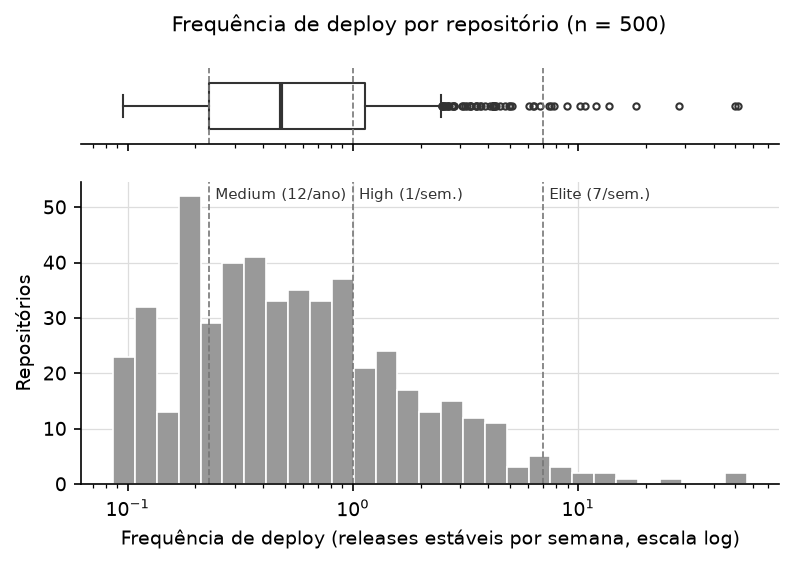

In [4]:
df = dados["deployment_frequency"].dropna()
cortes_df = {"Medium (12/ano)": 12 * 7 / 365, "High (1/sem.)": 1, "Elite (7/sem.)": 7}
bins = np.logspace(np.log10(df.min() * 0.9), np.log10(df.max() * 1.1), 30)

fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True, figsize=(6, 3.6), height_ratios=[1, 4])
ax_box.boxplot(df, vert=False, widths=0.6, showfliers=True,
               flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "none", "markeredgecolor": TINTA},
               medianprops={"color": TINTA, "linewidth": 2}, boxprops={"color": TINTA}, whiskerprops={"color": TINTA},
               capprops={"color": TINTA})
ax_box.set_yticks([])
ax_box.grid(False)
ax_box.spines["left"].set_visible(False)
ax_hist.hist(df, bins=bins, color=TINTA_CLARA, edgecolor="white", linewidth=0.8)
for rotulo, x in cortes_df.items():
    for ax in (ax_box, ax_hist):
        ax.axvline(x, color=CORTE, linestyle="--", linewidth=0.8)
    ax_hist.annotate(rotulo, (x, 1), xycoords=("data", "axes fraction"), xytext=(3, -3),
                     textcoords="offset points", va="top", fontsize=7, color=TINTA)
ax_hist.set_xscale("log")
ax_hist.set_xlabel("Frequência de deploy (releases estáveis por semana, escala log)")
ax_hist.set_ylabel("Repositórios")
fig.suptitle(f"Frequência de deploy por repositório (n = {len(df)})", fontsize=10)
fig.savefig(FIGURAS / "rq01_frequencia_deploy.png")
plt.show()

## RQ02 — Lead time

Variante (a): mediana, por release, de publicação − commit mais antigo. Variante (b): mediana de todos os pares commit–release. Ambas em horas.

Repositórios sem compare válido ficam fora do resumo; o `n` de cada variante está na tabela.

In [5]:
for variante in ("a", "b"):
    dados[f"lead_time_{variante}_dias"] = dados[f"lead_time_{variante}"] / DIA
rq02 = tabela_resumo(dados, {
    "Lead time (a), horas": "lead_time_a",
    "Lead time (b), horas": "lead_time_b",
    "Lead time (a), dias": "lead_time_a_dias",
    "Lead time (b), dias": "lead_time_b_dias",
})
rq02.to_csv(TABELAS / "rq02_resumo.csv", index=False)
rq02

,metrica,n,ausentes,minimo,q1,mediana,q3,iqr,maximo,media
0,"Lead time (a), horas",499,1,0.008,91.107,268.020,928.012,836.905,"50,633.772","1,876.069"
1,"Lead time (b), horas",499,1,0.008,79.463,303.217,"1,225.320","1,145.857","107,152.055","2,003.623"
2,"Lead time (a), dias",499,1,0.000,3.796,11.167,38.667,34.871,"2,109.741",78.170
3,"Lead time (b), dias",499,1,0.000,3.311,12.634,51.055,47.744,"4,464.669",83.484


### Comparação das variantes (a) e (b)

Pares do mesmo repositório. Diferença = (a) − (b), em horas; razão = (a) / (b). A hipótese da RQ02 espera (a) > (b).

In [6]:
pares = pares_lead_time(dados)
pares.to_csv(TABELAS / "rq02_pares_variantes.csv", index=False)
comparacao = pd.Series(comparar_variantes(pares), name="valor", dtype=object).to_frame()
comparacao.to_csv(TABELAS / "rq02_comparacao_variantes.csv")
display(pares.head(10))
comparacao

,id,full_name,lead_time_a,lead_time_b,diferenca,razao
0,8514,rails/rails,"40,313.957","12,554.201","27,759.757",3.211
1,156018,redis/redis,"10,274.714","20,646.767","-10,372.052",0.498
2,237159,expressjs/express,"10,700.924","9,766.233",934.691,1.096
3,458058,symfony/symfony,"12,205.901","10,636.576","1,569.325",1.148
4,507775,elastic/elasticsearch,"9,355.214","6,081.042","3,274.172",1.538
5,529502,scrapy/scrapy,"1,058.876",477.286,581.591,2.219
6,557980,socketio/socket.io,492.904,"107,152.055","-106,659.151",0.005
7,569041,curl/curl,"7,182.561",739.559,"6,443.001",9.712
8,571770,jgm/pandoc,726.085,344.762,381.323,2.106
9,576201,mrdoob/three.js,"1,774.586",836.390,938.196,2.122


,valor
n_pares,499
a_maior,303
iguais,1
a_menor,195
mediana_diferenca,27.567
mediana_razao,1.294


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_26572\3094981835.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(list(variantes.values()), vert=False, widths=0.5, tick_labels=list(variantes),


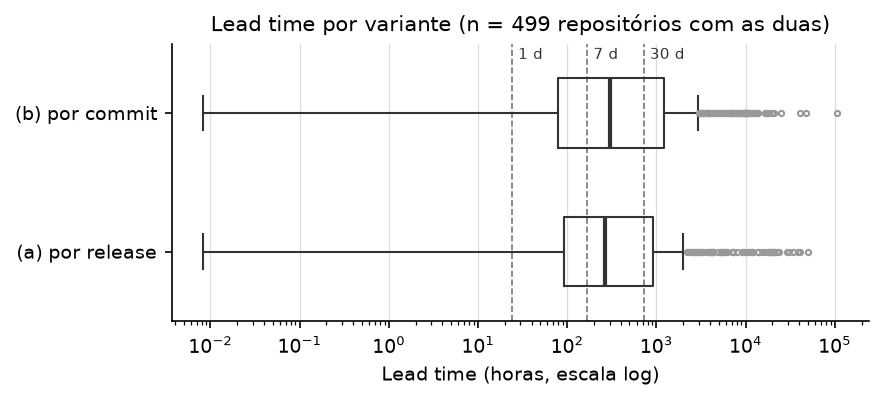

In [7]:
cortes_lt = {"1 d": DIA, "7 d": SEMANA, "30 d": MES}
variantes = {"(a) por release": pares["lead_time_a"], "(b) por commit": pares["lead_time_b"]}

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.boxplot(list(variantes.values()), vert=False, widths=0.5, tick_labels=list(variantes),
           flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": "none", "markeredgecolor": TINTA_CLARA},
           medianprops={"color": TINTA, "linewidth": 2}, boxprops={"color": TINTA}, whiskerprops={"color": TINTA},
           capprops={"color": TINTA})
for rotulo, x in cortes_lt.items():
    ax.axvline(x, color=CORTE, linestyle="--", linewidth=0.8, zorder=0)
    ax.annotate(rotulo, (x, 1), xycoords=("data", "axes fraction"), xytext=(3, -2),
                textcoords="offset points", va="top", fontsize=7, color=TINTA)
ax.set_xscale("log")
ax.set_xlabel("Lead time (horas, escala log)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Lead time por variante (n = {len(pares)} repositórios com as duas)", fontsize=10)
fig.savefig(FIGURAS / "rq02_lead_time_variantes.png")
plt.show()

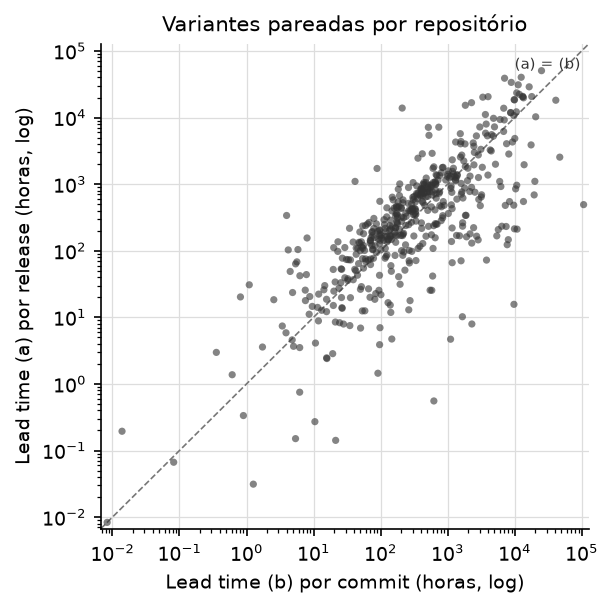

In [8]:
limites = [pares[["lead_time_a", "lead_time_b"]].min().min() * 0.8, pares[["lead_time_a", "lead_time_b"]].max().max() * 1.2]

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.plot(limites, limites, color=CORTE, linestyle="--", linewidth=0.8, zorder=1)
ax.annotate("(a) = (b)", (limites[1], limites[1]), xytext=(-4, -12), textcoords="offset points",
            ha="right", fontsize=7, color=TINTA)
ax.scatter(pares["lead_time_b"], pares["lead_time_a"], s=12, color=TINTA, alpha=0.6, edgecolor="none", zorder=2)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(limites)
ax.set_ylim(limites)
ax.set_xlabel("Lead time (b) por commit (horas, log)")
ax.set_ylabel("Lead time (a) por release (horas, log)")
ax.set_title("Variantes pareadas por repositório", fontsize=10)
fig.savefig(FIGURAS / "rq02_lead_time_pareado.png")
plt.show()

## Limitações

- O lead time depende do compare entre releases; repositórios sem compare válido têm `lead_time_a`/`lead_time_b` nulos e ficam fora do resumo.
- A amostra não é aleatória: a ordem da coleta priorizou custo nos 561 primeiros candidatos avaliados (ver o funil na metodologia), o que limita a generalização.
- A classificação DORA das métricas fica na S03-03 (#169).